# Phase 2 — EEG Inferential Statistics (Batch Analysis)

**Purpose:** Run the pre/post EEG comparisons and Experiment-vs-Control change comparisons across task, condition, band, and ROI, with transparent cohort counts, effect sizes, and Holm correction.

**Working decisions (provisional):** Relative band power is the primary metric; log10 absolute power is a complementary metric because Step 3C found strongly skewed absolute values and a high outlier-flag rate. All-observation analyses are primary; outlier-excluded analyses are sensitivity-only. This notebook does not diagnose artifacts or automatically remove participants.

Run from top to bottom. It locates `eeg_roi_power_long.csv` and saves outputs into `eeg_phase2_statistics_outputs/` beside the input.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, mannwhitneyu, norm
from statsmodels.stats.multitest import multipletests

INPUT_NAME = 'eeg_roi_power_long.csv'
search_roots = [Path.cwd(), Path.cwd().parent, Path('/mnt/data')]
input_path = next((root / INPUT_NAME for root in search_roots if (root / INPUT_NAME).exists()), None)
if input_path is None:
    matches = list(Path.cwd().rglob(INPUT_NAME))
    input_path = matches[0] if matches else None
if input_path is None:
    raise FileNotFoundError(f'Could not locate {INPUT_NAME}. Place it beside this notebook or in the analysis folder.')

OUT = input_path.parent / 'eeg_phase2_statistics_outputs'
OUT.mkdir(exist_ok=True)
d = pd.read_csv(input_path)
print('Input:', input_path)
print('Shape:', d.shape)
print('Output directory:', OUT)
print('Columns:', d.columns.tolist())

Input: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_roi_power_long.csv
Shape: (8000, 12)
Output directory: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_phase2_statistics_outputs
Columns: ['subject_id', 'session', 'run', 'condition', 'band', 'roi', 'absolute_power_roi', 'relative_power_roi', 'channels_in_roi', 'channel_rows_in_roi', 'task', 'group']


In [2]:
# Required schema and data checks
required = ['subject_id','session','condition','band','roi','absolute_power_roi','relative_power_roi','task','group']
missing_cols = [c for c in required if c not in d.columns]
if missing_cols:
    raise ValueError(f'Missing required columns: {missing_cols}')

for c in ['absolute_power_roi','relative_power_roi']:
    d[c] = pd.to_numeric(d[c], errors='coerce')

print('Missing power values:', d[['absolute_power_roi','relative_power_roi']].isna().sum().to_dict())
print('Non-positive absolute power:', (d['absolute_power_roi'] <= 0).sum())
print('Sessions:', sorted(d['session'].dropna().unique()))
print('Groups:', sorted(d['group'].dropna().unique()))
print('Tasks:', sorted(d['task'].dropna().unique()))
print('Conditions:', sorted(d['condition'].dropna().unique()))
# Duplicate keys are not silently collapsed.
key = ['subject_id','session','task','condition','band','roi']
dup = d.duplicated(key, keep=False)
print('Duplicate participant-session-task-condition-band-ROI keys:', dup.sum())
if dup.any():
    display(d.loc[dup].sort_values(key).head(30))

# Add analysis variables.
d['log10_absolute'] = np.where(d['absolute_power_roi'] > 0, np.log10(d['absolute_power_roi']), np.nan)

Missing power values: {'absolute_power_roi': 0, 'relative_power_roi': 0}
Non-positive absolute power: 0
Sessions: ['POST', 'PRE']
Groups: ['Control', 'Experiment']
Tasks: ['Math', 'Reading']
Conditions: ['Activity', 'Activity1', 'Activity2', 'Baseline']
Duplicate participant-session-task-condition-band-ROI keys: 0


## A. Descriptive summaries and coverage
These tables summarize data availability and the two EEG metrics. Coverage is shown by task × group × session × condition.

In [3]:
coverage = (d.groupby(['task','group','session','condition'], dropna=False)
             .agg(n_participants=('subject_id','nunique'), n_rows=('subject_id','size'))
             .reset_index())
coverage.to_csv(OUT/'phase2_coverage.csv', index=False)
desc = (d.groupby(['task','group','session','condition','band','roi'], dropna=False)
         .agg(n=('subject_id','count'), relative_mean=('relative_power_roi','mean'),
              relative_sd=('relative_power_roi','std'), relative_median=('relative_power_roi','median'),
              logabs_mean=('log10_absolute','mean'), logabs_sd=('log10_absolute','std'),
              logabs_median=('log10_absolute','median'))
         .reset_index())
desc.to_csv(OUT/'phase2_descriptive_summary.csv', index=False)
display(coverage.head(30)); display(desc.head(20))

,task,group,session,condition,n_participants,n_rows
0,Math,Control,POST,Activity1,15,375
1,Math,Control,POST,Activity2,15,375
2,Math,Control,POST,Baseline,15,375
3,Math,Control,PRE,Activity1,15,375
4,Math,Control,PRE,Activity2,15,375
5,Math,Control,PRE,Baseline,15,375
6,Math,Experiment,POST,Activity1,19,475
7,Math,Experiment,POST,Activity2,19,475
8,Math,Experiment,POST,Baseline,19,475
9,Math,Experiment,PRE,Activity1,19,475


,task,group,session,condition,band,roi,n,relative_mean,relative_sd,relative_median,logabs_mean,logabs_sd,logabs_median
0,Math,Control,POST,Activity1,alpha,Central,15,4.343004,2.486900,3.719769,3.176314,1.807488,3.335460
1,Math,Control,POST,Activity1,alpha,Frontal,15,3.706420,2.344001,3.282975,3.221695,1.796576,3.392571
2,Math,Control,POST,Activity1,alpha,Occipital,15,5.132007,2.202499,5.033358,5.384938,2.337395,6.112724
3,Math,Control,POST,Activity1,alpha,Parietal,15,5.132266,3.100336,4.282619,4.506369,2.162041,4.551327
4,Math,Control,POST,Activity1,alpha,Temporal,15,3.975488,2.200416,3.728603,4.669223,2.288215,4.469597
5,Math,Control,POST,Activity1,beta,Central,15,5.822637,5.026650,4.771796,3.232347,1.729078,3.319109
6,Math,Control,POST,Activity1,beta,Frontal,15,4.899291,4.380480,3.740650,3.282228,1.704556,3.374382
7,Math,Control,POST,Activity1,beta,Occipital,15,8.828812,7.283683,6.862504,5.566841,2.239151,6.376046
8,Math,Control,POST,Activity1,beta,Parietal,15,7.751626,6.612968,5.177164,4.610039,2.122038,5.086516
9,Math,Control,POST,Activity1,beta,Temporal,15,5.908490,4.404235,5.043050,4.748688,2.228645,4.714554


## B. Build PRE–POST pairs
Only participants with both PRE and POST in the same task-condition-band-ROI cell enter the paired tests. No participant-level exclusion is made here. Relative change is POST−PRE in percentage points. Log-absolute change is POST−PRE on the log10 scale (a log-ratio interpretation).

In [4]:
metrics = {'relative_power':'relative_power_roi', 'log10_absolute':'log10_absolute'}
base = ['subject_id','group','task','condition','band','roi']
wide = d.pivot_table(index=base, columns='session', values=list(metrics.values()), aggfunc='first')
# Flatten columns using analysis aliases (relative_power, log10_absolute).
reverse_metrics = {v:k for k,v in metrics.items()}
wide.columns = [f'{reverse_metrics[actual]}_{session}' for actual,session in wide.columns]
wide = wide.reset_index()
for metric in metrics:
    pre, post = f'{metric}_PRE', f'{metric}_POST'
    if pre in wide and post in wide:
        wide[f'{metric}_change_POST_minus_PRE'] = wide[post] - wide[pre]

pair_cols = [c for c in wide.columns if c.endswith('_PRE') or c.endswith('_POST') or '_change_POST_minus_PRE' in c]
paired = wide.dropna(subset=[c for c in pair_cols if c in wide.columns]).copy()
paired.to_csv(OUT/'phase2_prepost_paired_dataset.csv', index=False)
print('Wide participant rows:', len(wide), '| paired dataset rows:', len(paired))

Wide participant rows: 4000 | paired dataset rows: 4000


## C. Statistical tests

- **Within-group PRE–POST:** Wilcoxon signed-rank test (two-sided) for each group × task × condition × band × ROI × metric.
- **Between-group change:** Mann–Whitney U comparing POST−PRE change scores between Control and Experiment for each task × condition × band × ROI × metric.
- Effect sizes: paired Cohen's *dz* (mean paired change / SD of change) and rank-biserial effect for independent Mann–Whitney comparisons.
- Holm correction is applied separately within task × metric × test family (within-group tests pooled across their condition/band/ROI cells; between-group change tests pooled across those cells).

Small samples and ties may affect Wilcoxon behavior; the notebook records sample size and test failures rather than silently dropping results.

In [5]:
def safe_wilcoxon(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    diff = y - x
    n = len(diff)
    if n < 2 or np.allclose(diff, 0):
        return n, np.nan, np.nan, np.nan, np.nan
    try:
        res = wilcoxon(y, x, alternative='two-sided', zero_method='wilcox', method='auto')
        p = float(res.pvalue); stat = float(res.statistic)
        z = np.sign(np.mean(diff)) * norm.isf(max(p, 1e-300)/2)
        r = z / np.sqrt(n)
        dz = np.mean(diff) / np.std(diff, ddof=1) if np.std(diff, ddof=1)>0 else np.nan
        return n, stat, p, r, dz
    except Exception:
        return n, np.nan, np.nan, np.nan, np.nan


def safe_mwu(a, b):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a)<2 or len(b)<2:
        return len(a), len(b), np.nan, np.nan, np.nan
    try:
        res = mannwhitneyu(a, b, alternative='two-sided', method='auto')
        # U is for the first sample; rank-biserial orientation Experiment vs Control depends on input order.
        rb = 2*res.statistic/(len(a)*len(b))-1
        return len(a), len(b), float(res.statistic), float(res.pvalue), float(rb)
    except Exception:
        return len(a), len(b), np.nan, np.nan, np.nan

In [6]:
within_rows=[]
ind_rows=[]
change_col = {'relative_power':'relative_power_change_POST_minus_PRE',
              'log10_absolute':'log10_absolute_change_POST_minus_PRE'}
for metric in metrics:
    ch = change_col[metric]
    precol, postcol = metric+'_PRE', metric+'_POST'
    if ch not in paired.columns: continue
    for keys, cell in paired.groupby(['task','condition','band','roi'], dropna=False):
        task, condition, band, roi = keys
        for grp in ['Control','Experiment']:
            g = cell[cell.group==grp]
            if precol not in g or postcol not in g: continue
            n, stat, p, r, dz = safe_wilcoxon(g[precol], g[postcol])
            within_rows.append(dict(metric=metric, task=task, condition=condition, band=band, roi=roi,
                                  group=grp, n_pairs=n, statistic=stat, p_raw=p,
                                  effect_r_approx=r, paired_cohens_dz=dz,
                                  mean_change=np.nanmean(g[ch]) if n else np.nan,
                                  median_change=np.nanmedian(g[ch]) if n else np.nan))
        a = cell.loc[cell.group=='Experiment', ch]
        b = cell.loc[cell.group=='Control', ch]
        n_exp,n_ctrl,u,p,rb = safe_mwu(a,b)
        ind_rows.append(dict(metric=metric,task=task,condition=condition,band=band,roi=roi,
                            n_experiment=n_exp,n_control=n_ctrl,U_experiment_vs_control=u,
                            p_raw=p,rank_biserial_experiment_vs_control=rb,
                            mean_change_experiment=np.nanmean(a) if n_exp else np.nan,
                            mean_change_control=np.nanmean(b) if n_ctrl else np.nan,
                            median_change_experiment=np.nanmedian(a) if n_exp else np.nan,
                            median_change_control=np.nanmedian(b) if n_ctrl else np.nan))

within = pd.DataFrame(within_rows)
independent = pd.DataFrame(ind_rows)

In [7]:
# Holm adjustment grouped by task, metric, and test family.
if not within.empty:
    within['p_holm'] = np.nan
    for _, idx in within.groupby(['task','metric','group']).groups.items():
        pvals = within.loc[idx,'p_raw']
        valid = pvals.notna()
        if valid.any(): within.loc[pvals.index[valid],'p_holm'] = multipletests(pvals[valid], method='holm')[1]
if not independent.empty:
    independent['p_holm'] = np.nan
    for _, idx in independent.groupby(['task','metric']).groups.items():
        pvals = independent.loc[idx,'p_raw']
        valid = pvals.notna()
        if valid.any(): independent.loc[pvals.index[valid],'p_holm'] = multipletests(pvals[valid], method='holm')[1]

within.to_csv(OUT/'phase2_within_group_prepost_tests.csv', index=False)
independent.to_csv(OUT/'phase2_between_group_change_tests.csv', index=False)
print('Within-group tests:', len(within), '| between-group change tests:', len(independent))
display(within.sort_values('p_holm', na_position='last').head(20))
display(independent.sort_values('p_holm', na_position='last').head(20))

Within-group tests: 500 | between-group change tests: 250


,metric,task,condition,band,roi,group,n_pairs,statistic,p_raw,effect_r_approx,paired_cohens_dz,mean_change,median_change,p_holm
219,relative_power,Reading,Baseline,beta,Temporal,Experiment,17,20.0,0.005569,-0.672335,-0.699278,-13.131220,-8.752586,0.278473
237,relative_power,Reading,Baseline,gamma,Parietal,Experiment,17,21.0,0.006653,-0.658179,-0.764686,-7.146425,-7.466229,0.325989
229,relative_power,Reading,Baseline,delta,Temporal,Experiment,17,21.0,0.006653,0.658179,0.729968,23.582726,18.759864,0.325989
209,relative_power,Reading,Baseline,alpha,Temporal,Experiment,17,22.0,0.007904,-0.644209,-0.608264,-2.077413,-2.545537,0.371490
217,relative_power,Reading,Baseline,beta,Parietal,Experiment,17,22.0,0.007904,-0.644209,-0.765475,-12.568772,-10.877996,0.371490
133,relative_power,Math,Baseline,gamma,Frontal,Experiment,19,28.0,0.005329,-0.639252,-0.674415,-14.070920,-2.464301,0.399685
233,relative_power,Reading,Baseline,gamma,Frontal,Experiment,17,23.0,0.009338,-0.630450,-0.667104,-7.676472,-6.107891,0.420227
438,log10_absolute,Reading,Activity,gamma,Temporal,Control,12,7.0,0.009277,-0.751035,-0.957974,-2.481705,-2.394252,0.463867
201,relative_power,Reading,Baseline,alpha,Central,Experiment,17,24.0,0.010986,-0.616800,-0.487418,-3.018718,-3.177358,0.483398
227,relative_power,Reading,Baseline,delta,Parietal,Experiment,17,24.0,0.010986,0.616800,0.727461,22.727076,29.344954,0.483398


,metric,task,condition,band,roi,n_experiment,n_control,U_experiment_vs_control,p_raw,rank_biserial_experiment_vs_control,mean_change_experiment,mean_change_control,median_change_experiment,median_change_control,p_holm
116,relative_power,Reading,Baseline,gamma,Frontal,17,12,47.0,0.015809,-0.539216,-7.676472,1.319692,-6.107891,-0.074595,0.790439
118,relative_power,Reading,Baseline,gamma,Parietal,17,12,49.0,0.020086,-0.519608,-7.146425,2.664963,-7.466229,0.469291,0.984210
0,relative_power,Math,Activity1,alpha,Central,19,15,164.0,0.466386,0.150877,-0.482402,-0.952150,-0.194598,-0.923775,1.000000
159,log10_absolute,Math,Activity2,beta,Temporal,19,15,140.0,0.944696,-0.017544,0.092938,-0.135061,-0.466846,1.012583,1.000000
160,log10_absolute,Math,Activity2,delta,Central,19,15,125.0,0.555436,-0.122807,-0.263266,0.177116,0.166771,0.444945,1.000000
161,log10_absolute,Math,Activity2,delta,Frontal,19,15,124.0,0.532418,-0.129825,-0.188078,0.311045,0.123468,0.489201,1.000000
162,log10_absolute,Math,Activity2,delta,Occipital,19,15,119.0,0.425021,-0.164912,-0.762447,0.145986,-1.133300,-1.123693,1.000000
163,log10_absolute,Math,Activity2,delta,Parietal,19,15,123.0,0.509893,-0.136842,-0.603760,0.016486,0.206139,0.289713,1.000000
164,log10_absolute,Math,Activity2,delta,Temporal,19,15,150.0,0.808167,0.052632,0.401018,0.100574,-0.078218,0.860325,1.000000
165,log10_absolute,Math,Activity2,gamma,Central,19,15,117.0,0.385882,-0.178947,-0.736167,0.019068,-0.601082,0.351427,1.000000


## D. Sensitivity analysis — flag extreme log-absolute values, do not delete automatically
Flags are computed within task × group × session × condition × band × ROI using the union of IQR and MAD rules. For sensitivity, flagged participant-session observations are removed before pairing; only cells with both remaining PRE and POST are tested. This is an exploratory robustness check, not a primary analysis or artifact diagnosis.

In [8]:
flag_keys = ['task','group','session','condition','band','roi']
flags = pd.Series(False, index=d.index)
flag_details=[]
for key, idx in d.groupby(flag_keys, dropna=False).groups.items():
    vals = d.loc[idx,'absolute_power_roi'].astype(float)
    if len(vals)<4: continue
    q1,q3 = vals.quantile([.25,.75]); iqr=q3-q1
    iqr_flag = (vals < q1-1.5*iqr) | (vals > q3+1.5*iqr)
    med=vals.median(); mad=(vals-med).abs().median()
    mad_flag = ((vals-med).abs() > 3*1.4826*mad) if mad>0 else pd.Series(False,index=vals.index)
    flags.loc[idx] = iqr_flag | mad_flag

d_sens = d.loc[~flags].copy()
wide_sens = d_sens.pivot_table(index=base, columns='session', values=list(metrics.values()), aggfunc='first')
wide_sens.columns = [f'{reverse_metrics[actual]}_{session}' for actual,session in wide_sens.columns]
wide_sens=wide_sens.reset_index()
for metric in metrics:
    pre,post=f'{metric}_PRE',f'{metric}_POST'
    if pre in wide_sens and post in wide_sens:
        wide_sens[f'{metric}_change_POST_minus_PRE']=wide_sens[post]-wide_sens[pre]
paired_sens=wide_sens.dropna(subset=[c for c in wide_sens.columns if c.endswith('_PRE') or c.endswith('_POST')]).copy()

sens_within=[]; sens_ind=[]
for metric in metrics:
    ch=change_col[metric]; precol,postcol=metric+'_PRE',metric+'_POST'
    for keys,cell in paired_sens.groupby(['task','condition','band','roi'],dropna=False):
        task,condition,band,roi=keys
        for grp in ['Control','Experiment']:
            g=cell[cell.group==grp]
            n,stat,p,r,dz=safe_wilcoxon(g[precol],g[postcol])
            sens_within.append(dict(metric=metric,task=task,condition=condition,band=band,roi=roi,group=grp,n_pairs=n,statistic=stat,p_raw=p,effect_r_approx=r,paired_cohens_dz=dz,mean_change=g[ch].mean(),median_change=g[ch].median()))
        a=cell.loc[cell.group=='Experiment',ch]; b=cell.loc[cell.group=='Control',ch]
        ne,nc,u,p,rb=safe_mwu(a,b)
        sens_ind.append(dict(metric=metric,task=task,condition=condition,band=band,roi=roi,n_experiment=ne,n_control=nc,U_experiment_vs_control=u,p_raw=p,rank_biserial_experiment_vs_control=rb,mean_change_experiment=a.mean(),mean_change_control=b.mean()))
sw=pd.DataFrame(sens_within); si=pd.DataFrame(sens_ind)
for frame,groupcols in [(sw,['task','metric','group']),(si,['task','metric'])]:
    frame['p_holm']=np.nan
    for _,idx in frame.groupby(groupcols).groups.items():
        pvals=frame.loc[idx,'p_raw']; valid=pvals.notna()
        if valid.any(): frame.loc[pvals.index[valid],'p_holm']=multipletests(pvals[valid],method='holm')[1]
flags_frame=d.loc[flags].copy(); flags_frame['flag_iqr_mad_union']=True
flags_frame.to_csv(OUT/'phase2_logabsolute_flagged_rows.csv',index=False)
sw.to_csv(OUT/'phase2_sensitivity_within_group_tests_flagged_removed.csv',index=False)
si.to_csv(OUT/'phase2_sensitivity_between_group_tests_flagged_removed.csv',index=False)

## E. Primary/sensitivity comparison and plots
This section provides a compact comparison of corrected significance counts and visualizes the paired change distributions. Interpretation must consider effect size, sample size, data coverage, and corrected p-values—not significance alone.

,analysis,within_tests,within_Holm_sig,between_tests,between_Holm_sig
0,Primary (all observations),500,0,250,0
1,Sensitivity (flagged absolute rows removed),500,0,250,1


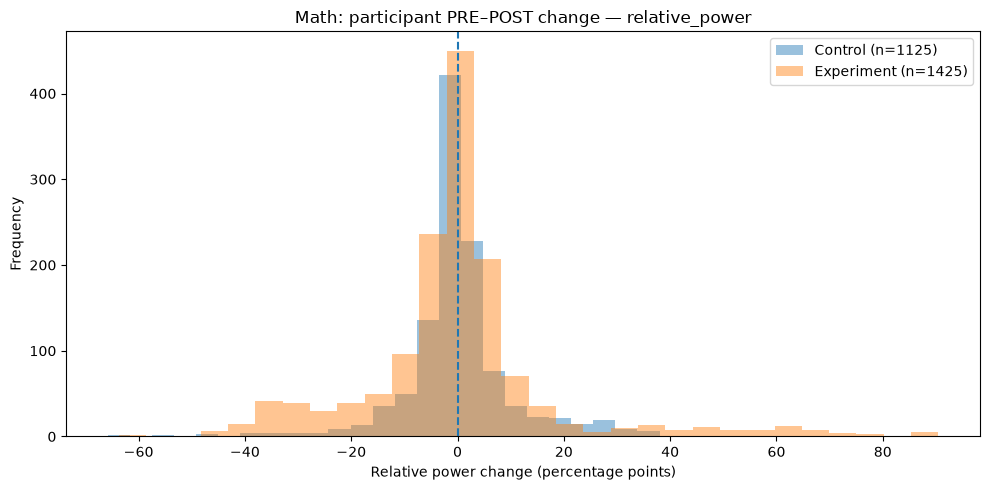

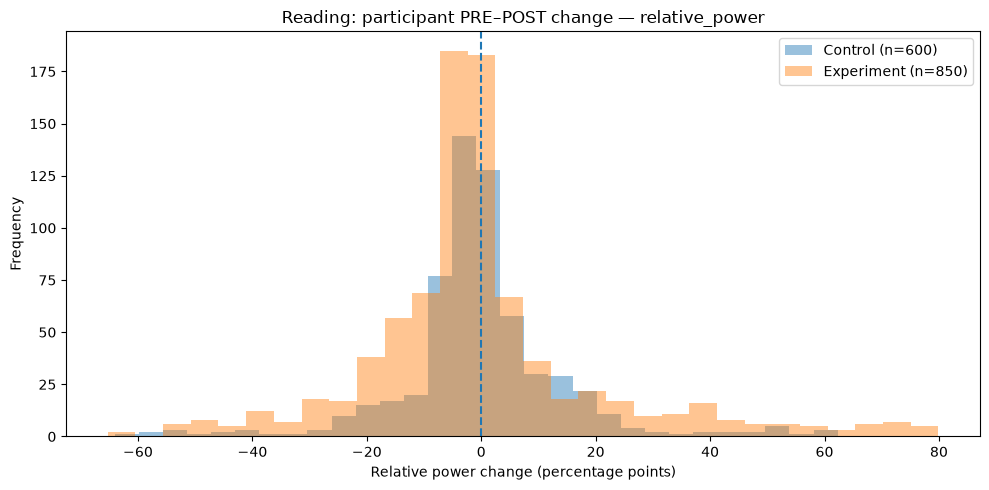

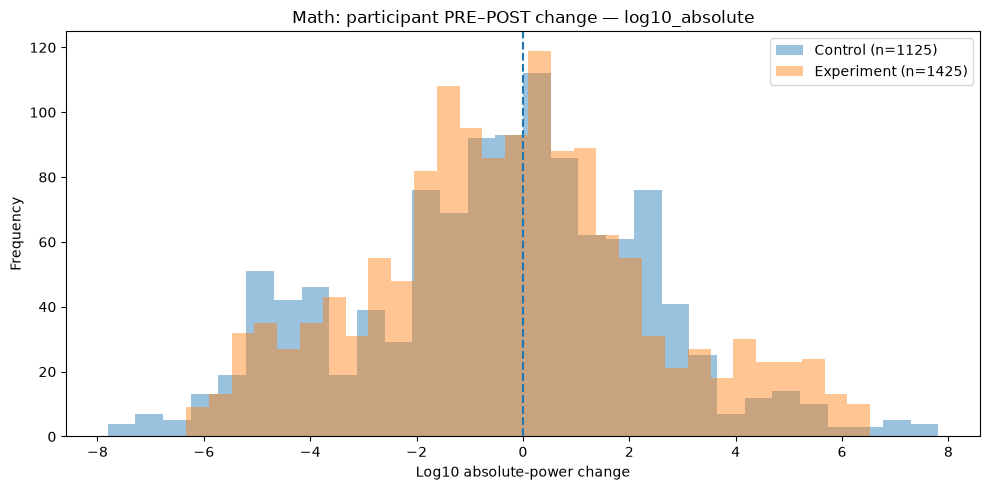

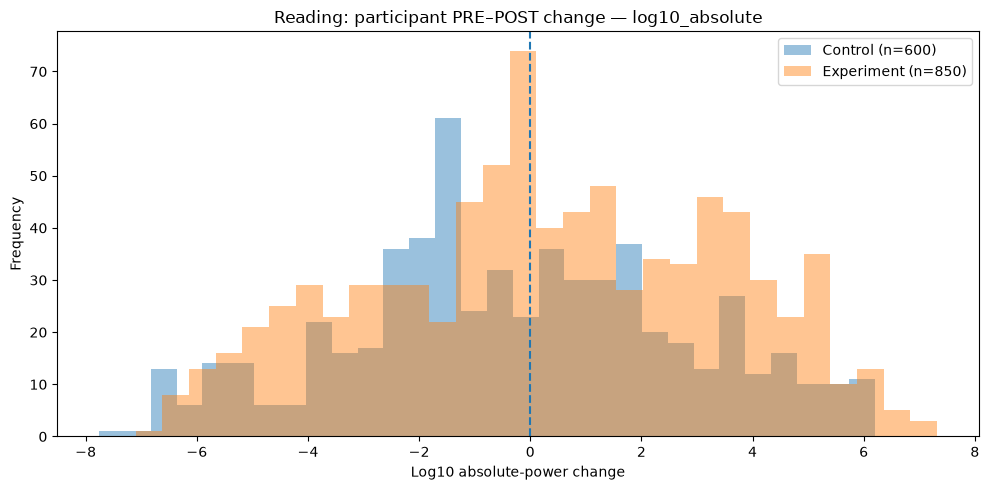

In [9]:
def count_significant(frame, pcol='p_holm'):
    if frame.empty or pcol not in frame: return 0
    return int((frame[pcol] < .05).sum())
comparison = pd.DataFrame([
    {'analysis':'Primary (all observations)','within_tests':len(within),'within_Holm_sig':count_significant(within),'between_tests':len(independent),'between_Holm_sig':count_significant(independent)},
    {'analysis':'Sensitivity (flagged absolute rows removed)','within_tests':len(sw),'within_Holm_sig':count_significant(sw),'between_tests':len(si),'between_Holm_sig':count_significant(si)}
])
comparison.to_csv(OUT/'phase2_primary_vs_sensitivity_counts.csv',index=False)
display(comparison)

# Participant paired change distributions, aggregated only for plotting by task/metric/group.
for metric, label in [('relative_power','Relative power change (percentage points)'),('log10_absolute','Log10 absolute-power change')]:
    ch=change_col[metric]
    for task in sorted(paired['task'].dropna().unique()):
        plotdata=paired[paired.task==task]
        if plotdata.empty: continue
        fig,ax=plt.subplots(figsize=(10,5))
        for grp in ['Control','Experiment']:
            vals=plotdata.loc[plotdata.group==grp,ch].dropna()
            if len(vals): ax.hist(vals, bins=30, alpha=.45, label=f'{grp} (n={len(vals)})')
        ax.axvline(0, linestyle='--')
        ax.set_title(f'{task}: participant PRE–POST change — {metric}')
        ax.set_xlabel(label); ax.set_ylabel('Frequency'); ax.legend(); plt.tight_layout()
        fig.savefig(OUT/f'change_histogram_{task}_{metric}.png',dpi=160)
        plt.show()

## F. Completion audit / export manifest
Review all outputs before claiming Phase 2 is complete. Statistical execution is complete only if the notebook runs without errors; scientific review still requires checking coverage, effect sizes, corrected results, sensitivity consistency, and whether conclusions are supported.

In [10]:
manifest = pd.DataFrame({'file':[p.name for p in sorted(OUT.iterdir()) if p.is_file()]})
manifest.to_csv(OUT/'phase2_output_manifest.csv',index=False)
print(f'Phase 2 outputs saved in: {OUT}')
print('Output files:')
for p in sorted(OUT.iterdir()):
    if p.is_file(): print('-',p.name)

Phase 2 outputs saved in: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_phase2_statistics_outputs
Output files:
- change_histogram_Math_log10_absolute.png
- change_histogram_Math_relative_power.png
- change_histogram_Reading_log10_absolute.png
- change_histogram_Reading_relative_power.png
- phase2_between_group_change_tests.csv
- phase2_coverage.csv
- phase2_descriptive_summary.csv
- phase2_logabsolute_flagged_rows.csv
- phase2_output_manifest.csv
- phase2_prepost_paired_dataset.csv
- phase2_primary_vs_sensitivity_counts.csv
- phase2_sensitivity_between_group_tests_flagged_removed.csv
- phase2_sensitivity_within_group_tests_flagged_removed.csv
- phase2_within_group_prepost_tests.csv
